In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
os.chdir('/content/drive/My Drive/Colab Notebooks/ICT110')


print("Current folder:", os.getcwd())
print("Files here:", os.listdir('.')[:10])

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Current folder: /content/drive/My Drive/Colab Notebooks/ICT110
Files here: ['ICT110_ASSIGNMENT_EXCERCISE_2.1.ipynb', 'Datasets']


## Exercise 2.1

Load to a dataframe the file `GDP(PPP)_LifeExpectancy.xlsx` in the folder `Datasets`.
- Don't load the column Code which contains the full name of the country
- Use the following column names: 'Country', 'Life_Exp', 'GDP', 'Population', 'Inc_Class'
- Encode invalid values to `np.nan`

In [ ]:
import pandas as pd
import numpy as np

file_path = r'/content/drive/My Drive/Colab Notebooks/ICT110/Datasets/GDP(PPP)_LifeExpectancy.xlsx'

df_raw = pd.read_excel(file_path)
df_subset = df_raw.iloc[:, [0, 2, 4]]
df_subset.columns = ['Country', 'Indicator', 'Value']

df_gdp = df_subset.pivot_table(index='Country', columns='Indicator', values='Value', aggfunc='first').reset_index()

new_columns = {}
for col in df_gdp.columns:
    if 'Life expectancy' in col:
        new_columns[col] = 'Life_Exp'
    elif 'GDP per capita' in col:
        new_columns[col] = 'GDP'
    elif 'Population' in col:
        new_columns[col] = 'Population'

df_gdp = df_gdp.rename(columns=new_columns)

df_gdp['Inc_Class'] = np.nan

final_cols = ['Country', 'Life_Exp', 'GDP', 'Population', 'Inc_Class']
for c in final_cols:
    if c not in df_gdp.columns:
        df_gdp[c] = np.nan

df_gdp = df_gdp[final_cols]

display(df_gdp.head())

Indicator,Country,Life_Exp,GDP,Population,Inc_Class
0,Afghanistan,60.702,1765.538028,NaN,NaN
1,Albania,78.414,9755.92876,NaN,NaN
2,Algeria,74.144,14201.365991,NaN,NaN
3,American Samoa,72.587,..,NaN,NaN
4,Andorra,84.197,43853.171239,NaN,NaN


## Exercise 3.1

The BitCoin Year-on-Year price data in CSV format could be found in this link: https://api.blockchain.info/charts/market-price?format=csv.
1. Download a copy of the CSV file and observe its characteristics.
2. Load the file directly from the url/website and assign it to a DataFrame called `df_bitcoin`
3. Plot the data

,Price
Date,
2025-10-27,114531.59
2025-10-28,114121.46
2025-10-29,112923.91
2025-10-30,110068.52
2025-10-31,108303.21


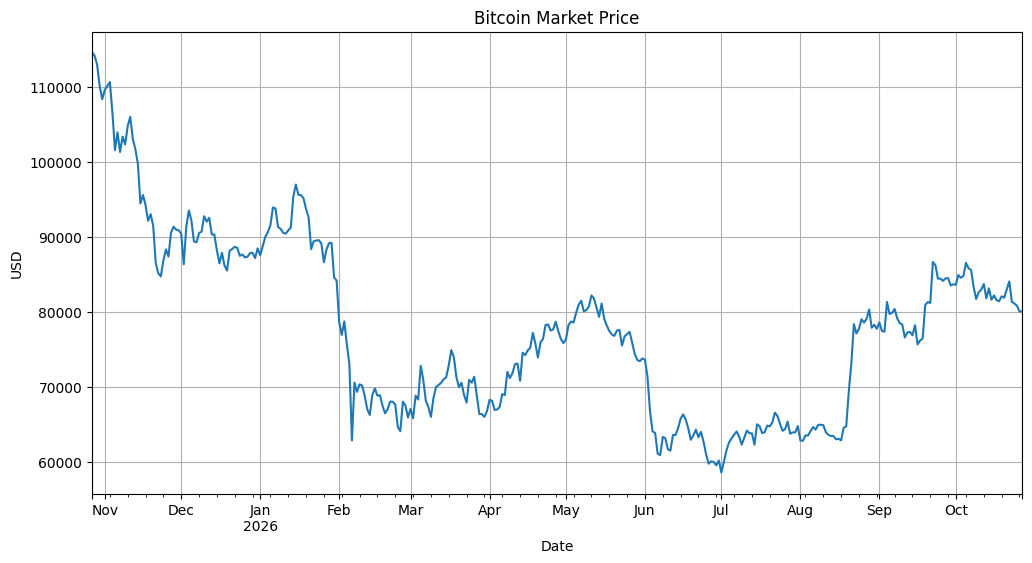

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

bitcoin_url = 'https://api.blockchain.info/charts/market-price?format=csv'

df_bitcoin = pd.read_csv(
    bitcoin_url,
    header=None,
    names=['Date', 'Price'],
    parse_dates=['Date']
)

df_bitcoin.set_index('Date', inplace=True)

display(df_bitcoin.head())

plt.figure(figsize=(12, 6))
df_bitcoin['Price'].plot(title='Bitcoin Market Price', ylabel='USD')
plt.grid(True)
plt.show()

## Exercise 4.1

Answer the following questions regarding the `df_gdp` you created in Exercise 2.1:
  1. What are the dimensions of the DataFrame?
  2. How many valid GDP values are there?
  3. What is the average life expectancy for all countries?
  4. Sort the dataframe by Country and assign it to a new DataFrame
  5. What are the top 5 countries with the highest GDP?
  6. What are the top 5 countries with smallest population?

In [ ]:
df_gdp['GDP'] = pd.to_numeric(df_gdp['GDP'], errors='coerce')
df_gdp['Life_Exp'] = pd.to_numeric(df_gdp['Life_Exp'], errors='coerce')
df_gdp['Population'] = pd.to_numeric(df_gdp['Population'], errors='coerce')

print("1. Dimensions:", df_gdp.shape)

print("\n2. Valid GDP values:", df_gdp['GDP'].count())

print("\n3. Average Life Expectancy:", df_gdp['Life_Exp'].mean())

print("\n4. Sorted DataFrame by Country assigned to df_sorted.")
df_sorted = df_gdp.sort_values('Country')
display(df_sorted)

print("\n5. Top 5 countries with highest GDP:")
display(df_gdp.nlargest(5, 'GDP')[['Country', 'GDP']])

print("\n6. Top 5 countries with smallest population:")
display(df_gdp.nsmallest(5, 'Population')[['Country', 'Population']])

1. Dimensions: (217, 5)

2. Valid GDP values: 201

3. Average Life Expectancy: 70.77860672136676

4. Sorted DataFrame by Country assigned to df_sorted.


Indicator,Country,Life_Exp,GDP,Population,Inc_Class
0,Afghanistan,60.702000,1765.538028,NaN,NaN
1,Albania,78.414000,9755.928760,NaN,NaN
2,Algeria,74.144000,14201.365991,NaN,NaN
3,American Samoa,72.587000,NaN,NaN,NaN
4,Andorra,84.197000,43853.171239,NaN,NaN
...,...,...,...,...,...
212,Virgin Islands (U.S.),77.865854,41607.566857,NaN,NaN
213,West Bank and Gaza,73.302000,4120.860663,NaN,NaN
214,"Yemen, Rep.",67.223000,3603.035056,NaN,NaN
215,Zambia,56.896000,3097.664005,NaN,NaN



5. Top 5 countries with highest GDP:


Indicator,Country,GDP
159,Qatar,151646.217415
117,"Macao SAR, China",99831.766339
116,Luxembourg,90346.068827
204,United Arab Emirates,83670.909374
28,Brunei Darussalam,79542.677876



6. Top 5 countries with smallest population:


Indicator,Country,Population
0,Afghanistan,NaN
1,Albania,NaN
2,Algeria,NaN
3,American Samoa,NaN
4,Andorra,NaN
